In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from odtlearn.bertsimasdunn_oct import BertsimasDunnOCT

# `BertsimasDunnOCT` Examples

## Example 1: Toy example
In this part, we study a simple example and investigate different parameter combinations to provide intuition on how they affect the structure of the tree.

First we generate the data for our example. The diagram within the code block shows the training dataset. Our dataset has two binary features (X0 and X1) and two class labels (+1 and -1).

In [2]:
from odtlearn.datasets import flow_oct_example

"""
    X1
    |               |
    |               |
    1    + +        |    -
    |               |   
    |---------------|-------------
    |               |
    0    - - - -    |    + + +
    |    - - -      |
    |______0________|_______1_______X0
"""


X, y = flow_oct_example()

### Tree with `depth = 1`

In the following, we fit a classification tree of depth 1, i.e., a tree with a single branching node and two leaf nodes.

In [3]:
stcl = BertsimasDunnOCT(depth=1, solver="gurobi", time_limit=100)
stcl.fit(X, y)

Set parameter Username
Academic license - for non-commercial use only - expires 2027-01-19
Set parameter TimeLimit to value 100
Gurobi Optimizer version 13.0.2 build v13.0.2rc1 (mac64[rosetta2] - Darwin 25.3.0 25D2128)

CPU model: Apple M5
Thread count: 10 physical cores, 10 logical processors, using up to 10 threads

Non-default parameters:
TimeLimit  100

Optimize a model with 98 rows, 44 columns and 318 nonzeros (Min)
Model fingerprint: 0x2a5e77a2
Model has 2 linear objective coefficients
Variable types: 9 continuous, 35 integer (35 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+01]
  Objective range  [2e-01, 2e-01]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 1e+01]

Found heuristic solution: objective 1.0000000
Presolve removed 89 rows and 36 columns
Presolve time: 0.00s
Presolved: 9 rows, 8 columns, 32 nonzeros
Variable types: 0 continuous, 8 integer (4 binary)

Root relaxation: objective 7.169811e-02, 5 iterations, 0.00 seconds (0.00 work units)

 

BertsimasDunnOCT(solver=gurobi,depth=1,time_limit=100,num_threads=None,verbose=False)

In [4]:
predictions = stcl.predict(X)
print(f'Optimality gap is {stcl.optim_gap}')
print(f"In-sample accuracy is {np.sum(predictions==y)/y.shape[0]}")

Optimality gap is 0.0
In-sample accuracy is 0.7692307692307693


Users can access statistics from the optimization run such as optimality gap, number of nodes, number of constraints, etc. Directly as properties of the initialized class or through the `_solver` object. For example, one can access the optimality gap and the number of solutions after fitting the optimal decision tree through the `optim_gap` and `num_solutions` properties.

In [5]:
print(f'Optimality gap is {stcl.optim_gap}')
print(f'Number of solutions {stcl.num_solutions}')

Optimality gap is 0.0
Number of solutions 2


As we can see above, we find the optimal tree and the in-sample accuracy is 76%.

ODTlearn provides two different ways of visualizing the structure of the tree. The first method prints the structure of the tree in the console:

In [6]:
stcl.print_tree()

#########node  1
branch on X_0, threshold=1.0
#########node  2
leaf 0
#########node  3
leaf 1


The second method plots the structure of the tree using `matplotlib`:

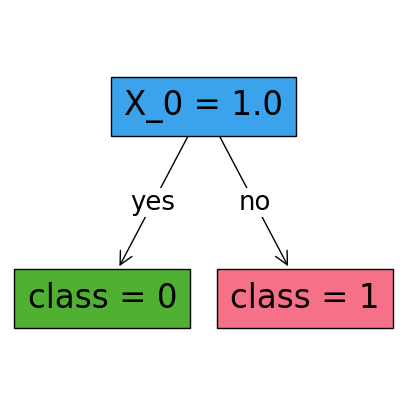

In [7]:
fig, ax = plt.subplots(figsize=(5, 5))
stcl.plot_tree(ax=ax)
plt.show()

### Tree with `depth = 2`

Now we increase the depth of the tree to achieve higher accuracy.

In [8]:
stcl = BertsimasDunnOCT(depth=2, solver="gurobi")
stcl.fit(X, y)

Set parameter TimeLimit to value 60
Gurobi Optimizer version 13.0.2 build v13.0.2rc1 (mac64[rosetta2] - Darwin 25.3.0 25D2128)

CPU model: Apple M5
Thread count: 10 physical cores, 10 logical processors, using up to 10 threads

Non-default parameters:
TimeLimit  60

Optimize a model with 265 rows, 92 columns and 867 nonzeros (Min)
Model fingerprint: 0x2a90c146
Model has 4 linear objective coefficients
Variable types: 19 continuous, 73 integer (73 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+01]
  Objective range  [2e-01, 2e-01]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 1e+01]

Found heuristic solution: objective 1.0000000
Presolve removed 195 rows and 52 columns
Presolve time: 0.01s
Presolved: 70 rows, 40 columns, 236 nonzeros
Variable types: 0 continuous, 40 integer (29 binary)

Root relaxation: objective 0.000000e+00, 27 iterations, 0.00 seconds (0.00 work units)

    Nodes    |    Current Node    |     Objective Bounds      |     Work
 Expl Unexpl

BertsimasDunnOCT(solver=gurobi,depth=2,time_limit=60,num_threads=None,verbose=False)

In [9]:
predictions = stcl.predict(X)
print(f"In-sample accuracy is {np.sum(predictions==y)/y.shape[0]}")

In-sample accuracy is 1.0


As we can see, with depth 2, we can achieve 100% in-sample accuracy.

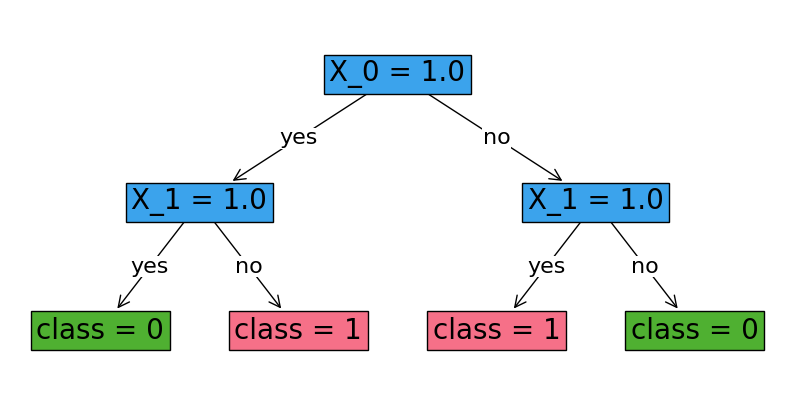

In [10]:
fig, ax = plt.subplots(figsize=(10, 5))
stcl.plot_tree(ax=ax, fontsize=20)
plt.show()

### Tree with `depth=2` and Positive `alpha`

As we saw in the above example, with depth 2, we can fully classify the training data. However if we add a regularization term with a high enough value of `_lambda`, we can justify pruning one of the branching nodes to get a sparser tree. In the following, we observe that as we increase `_lambda` from 0 to 0.51, one of the branching nodes gets pruned and as a result, the in-sample accuracy drops to 92%.

In [11]:
stcl = BertsimasDunnOCT(solver="gurobi", depth=2, alpha=0.2)
stcl.fit(X, y)

Set parameter TimeLimit to value 60
Gurobi Optimizer version 13.0.2 build v13.0.2rc1 (mac64[rosetta2] - Darwin 25.3.0 25D2128)

CPU model: Apple M5
Thread count: 10 physical cores, 10 logical processors, using up to 10 threads

Non-default parameters:
TimeLimit  60

Optimize a model with 265 rows, 92 columns and 867 nonzeros (Min)
Model fingerprint: 0xc8fc728e
Model has 7 linear objective coefficients
Variable types: 19 continuous, 73 integer (73 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+01]
  Objective range  [2e-01, 2e-01]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 1e+01]

Found heuristic solution: objective 1.0000000
Presolve removed 195 rows and 52 columns
Presolve time: 0.01s
Presolved: 70 rows, 40 columns, 236 nonzeros
Variable types: 0 continuous, 40 integer (29 binary)

Root relaxation: objective 6.711409e-03, 29 iterations, 0.00 seconds (0.00 work units)

    Nodes    |    Current Node    |     Objective Bounds      |     Work
 Expl Unexpl

BertsimasDunnOCT(solver=gurobi,depth=2,time_limit=60,num_threads=None,verbose=False)

In [12]:
predictions = stcl.predict(X)
print(f"In-sample accuracy is {np.sum(predictions==y)/y.shape[0]}")

In-sample accuracy is 0.9230769230769231


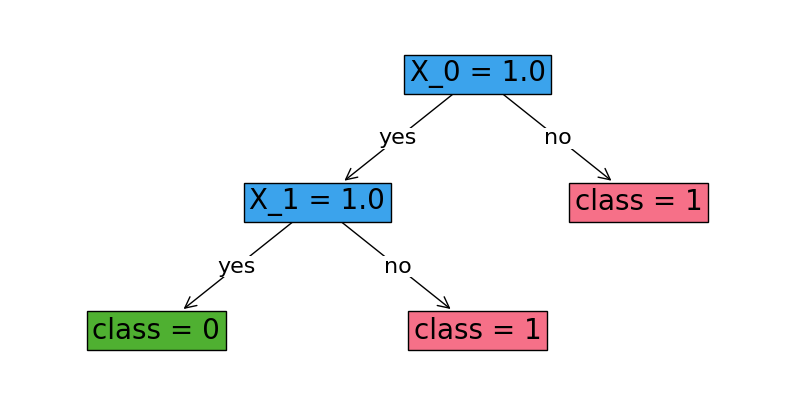

In [13]:
fig, ax = plt.subplots(figsize=(10, 5))
stcl.plot_tree(ax=ax, fontsize=20)
plt.show()

## Example 3: UCI Data Example

In this section, we fit a tree of depth 2 on a real world dataset called the [`balance` dataset](https://archive.ics.uci.edu/ml/datasets/Balance+Scale) from the UCI Machine Learning repository.
The data has been binarized. Although the BertsimasDunnOCT formulation does not require binary features, it does require all features to be normalized to be between 0 and 1.

In [14]:
import pandas as pd
from sklearn.model_selection import train_test_split
from odtlearn.datasets import balance_scale_data

In [15]:
# read data
data = balance_scale_data()
print(f"shape{data.shape}")
data.columns

shape(625, 21)


Index(['V2.1', 'V2.2', 'V2.3', 'V2.4', 'V2.5', 'V3.1', 'V3.2', 'V3.3', 'V3.4',
       'V3.5', 'V4.1', 'V4.2', 'V4.3', 'V4.4', 'V4.5', 'V5.1', 'V5.2', 'V5.3',
       'V5.4', 'V5.5', 'target'],
      dtype='str')

In [16]:
y = data.pop("target") # Target is the label

# Separate data into train and test
X_train, X_test, y_train, y_test = train_test_split(
    data, y, test_size=0.33, random_state=42
)

Note that with the BertsimasDunnOCT formulation, a candidate optimal solution may not yield a valid tree - only optimal trees will. To fix this, we would potentially need to change the formulation significantly.
For `depth=2`, BertsimasDunnOCT should be able to solve the problem on this dataset to optimality.

In [17]:
stcl = BertsimasDunnOCT(solver="gurobi", depth=2, time_limit=200, verbose=True)
stcl.store_search_progress_log = True
stcl.fit(X_train, y_train)

Set parameter Username
Academic license - for non-commercial use only - expires 2027-01-19
Set parameter TimeLimit to value 200
Gurobi Optimizer version 13.0.2 build v13.0.2rc1 (mac64[rosetta2] - Darwin 25.3.0 25D2128)

CPU model: Apple M5
Thread count: 10 physical cores, 10 logical processors, using up to 10 threads

Non-default parameters:
TimeLimit  200

Optimize a model with 7162 rows, 1774 columns and 60397 nonzeros (Min)
Model fingerprint: 0xb8ac22cc
Model has 4 linear objective coefficients
Variable types: 23 continuous, 1751 integer (1751 binary)
Coefficient statistics:
  Matrix range     [1e+00, 4e+02]
  Objective range  [5e-03, 5e-03]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 4e+02]

Presolve removed 418 rows and 0 columns
Presolve time: 0.04s
Presolved: 6744 rows, 1774 columns, 56233 nonzeros
Variable types: 0 continuous, 1774 integer (1754 binary)
Found heuristic solution: objective 1.0000000
Found heuristic solution: objective 0.9495413

Root relaxation:

BertsimasDunnOCT(solver=gurobi,depth=2,time_limit=200,num_threads=None,verbose=True)

In [18]:
stcl.print_tree()

#########node  1
branch on V3.1, threshold=1.0
#########node  2
branch on V2.1, threshold=1.0
#########node  3
branch on V5.1, threshold=1.0
#########node  4
leaf 2
#########node  5
leaf 3
#########node  6
leaf 3
#########node  7
leaf 2


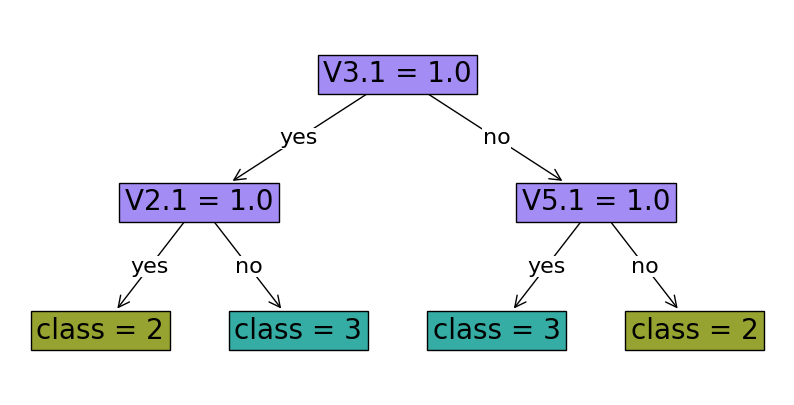

In [19]:
fig, ax = plt.subplots(figsize=(10, 5))
stcl.plot_tree(ax=ax, fontsize=20, color_dict={"node": None, "leaves": []})
plt.show()

In [20]:
test_pred = stcl.predict(X_test)
print('The out-of-sample accuracy is {}'.format(np.sum(test_pred==y_test)/y_test.shape[0]))

The out-of-sample accuracy is 0.6473429951690821


We also provide a simple function allowing users to plot the search progress log over time. Note that you must set the attribute `store_search_progress_log` to `True` before calling the `fit` method to ensure that the bound information is stored. 

<Axes: title={'center': 'Search Progress'}, xlabel='Time (s)', ylabel='Objective Bound'>

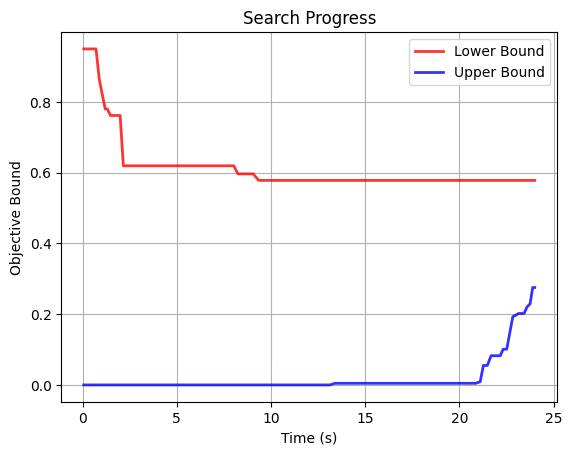

In [21]:
stcl.plot_search_progress()